# 📊 EconoCausal Walkthrough 01: Observational Confounding, DAGs & Propensity Weighting

**EconoCausal Production Walkthrough Series**  
*Causal Inference Engine for E-Commerce & Retail Promotion Optimization*

---

## 🎯 Objectives
In this notebook, we explore the fundamental challenge of causal inference in promotional marketing:
1. **Confounding Bias & Simpson's Paradox**: Understand why naive correlation leads to massive budget misallocation in observational promotional data.
2. **Structural Causal Modeling (DAGs)**: Formulate causal relationships with Directed Acyclic Graphs (DAGs) and verify identification via Pearl's Backdoor Criterion using **DoWhy**.
3. **Propensity Score Modeling**: Fit multi-class propensity scores $e(X) = P(T = t \mid X)$ to assess covariate balance and the **Positivity / Common Support** assumption.
4. **Inverse Probability Weighting (IPW)**: Compute de-biased Average Treatment Effects (ATE) and benchmark against ground truth synthetic potential outcomes.


In [1]:
import sys
from pathlib import Path

# Add project root to path for local src module imports
for candidate in [Path(".").resolve(), Path("..").resolve(), Path("../..").resolve()]:
    if (candidate / "src").exists():
        if str(candidate) not in sys.path:
            sys.path.insert(0, str(candidate))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# EconoCausal library imports
from src.data_gen import generate_data, compute_true_uplift, DISCOUNT_LEVELS, LOYALTY_TIERS
from src.causal_model import (
    build_dag,
    identify_effect,
    get_dag_dot,
    fit_propensity,
    overlap_report,
    balance_table,
    CONFOUNDERS,
)

# Set plotting styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 11

print("EconoCausal environment & core modules successfully initialized.")


C:\Users\anmol\Documents\EconoCausal\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


EconoCausal environment & core modules successfully initialized.


## 1. Observational Campaign Data Generation

In real-world retail promotions, discounts are rarely assigned uniformly at random:
- High-value loyalty customers (**Gold tier**) or high-spend customers are frequently targeted with generous promotions ($20).
- Customers who shop frequently (**low recency days**) or exhibit strong affinity are prioritized by automated CRM heuristics.

This creates **confounding**: the features determining promotion assignment also directly influence purchase probability.


In [2]:
# Generate observational cohort of 10,000 customers
N_CUSTOMERS = 10000
df = generate_data(n=N_CUSTOMERS, seed=42)

print(f"Dataset generated: {df.shape[0]:,} rows, {df.shape[1]} columns")
display_cols = ['customer_id', 'past_spend', 'recency_days', 'loyalty_tier', 'category_affinity', 'discount', 'purchase', 'true_effect']
df[display_cols].head(8)


Dataset generated: 10,000 rows, 9 columns


,customer_id,past_spend,recency_days,loyalty_tier,category_affinity,discount,purchase,true_effect
0,1,119.44,323,Bronze,0.3573,10,1,0.10094
1,2,53.30,286,Gold,0.6662,20,1,0.16162
2,3,156.06,250,Silver,0.3087,20,0,0.14672
3,4,174.92,92,Silver,0.2789,10,1,0.08010
4,5,30.86,227,Silver,0.4395,0,0,0.00000
5,6,45.54,300,Bronze,0.5133,10,0,0.12036
6,7,107.42,27,Silver,0.3531,20,1,0.13395
7,8,82.29,65,Silver,0.5803,0,0,0.00000


In [3]:
# Summary statistics across features
df.describe(include='all').T[['count', 'mean', 'std', 'min', '50%', 'max']]


,count,mean,std,min,50%,max
customer_id,10000.0,5000.5,2886.89568,1.0,5000.5,10000.0
past_spend,10000.0,118.649446,78.846662,10.0,98.7,1000.0
recency_days,10000.0,184.8917,105.093149,1.0,186.0,365.0
loyalty_tier,10000,NaN,NaN,NaN,NaN,NaN
age,10000.0,41.8579,13.511105,18.0,42.0,80.0
category_affinity,10000.0,0.497969,0.202858,0.0113,0.49615,0.996
discount,10000.0,8.421,7.915998,0.0,10.0,20.0
purchase,10000.0,0.359,0.479731,0.0,0.0,1.0
true_effect,10000.0,0.062666,0.060634,0.0,0.06791,0.21148


## 2. The Naive Fallacy & Simpson's Paradox

Let's compute the **naive conversion rate** by discount level:
$$\widehat{\text{CR}}_{\text{naive}}(t) = \mathbb{E}[Y \mid T = t]$$


In [4]:
naive_stats = df.groupby('discount').agg(
    n_customers=('customer_id', 'count'),
    mean_purchase=('purchase', 'mean'),
    mean_past_spend=('past_spend', 'mean'),
    pct_gold=('loyalty_tier', lambda s: (s == 'Gold').mean() * 100)
).reset_index()

naive_stats['naive_lift_vs_0'] = naive_stats['mean_purchase'] - naive_stats.loc[naive_stats['discount'] == 0, 'mean_purchase'].values[0]
naive_stats


,discount,n_customers,mean_purchase,mean_past_spend,pct_gold,naive_lift_vs_0
0,0,4047,0.234989,99.194779,12.008895,0.000000
1,10,3485,0.396557,123.079621,15.179340,0.161568
2,20,2468,0.509319,144.295263,19.367909,0.274330


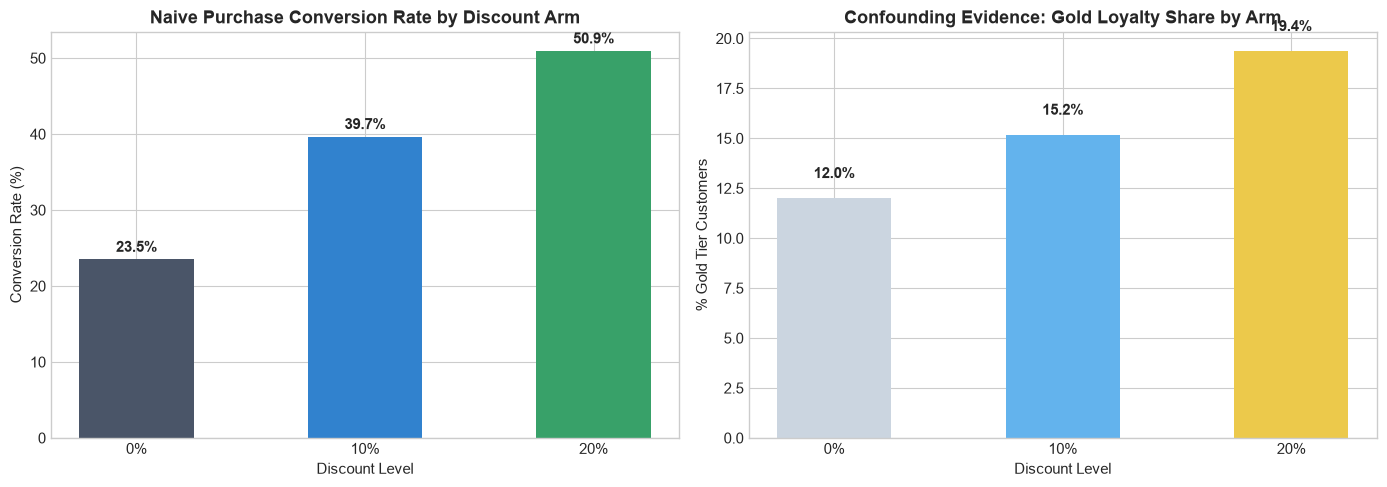

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Naive conversion rate by discount
ax1 = axes[0]
bars1 = ax1.bar(
    [str(d) + "%" for d in naive_stats['discount']],
    naive_stats['mean_purchase'] * 100,
    color=['#4A5568', '#3182CE', '#38A169'],
    width=0.5
)
ax1.set_title("Naive Purchase Conversion Rate by Discount Arm", fontweight="bold")
ax1.set_ylabel("Conversion Rate (%)")
ax1.set_xlabel("Discount Level")
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + 1.0, f"{yval:.1f}%", ha='center', fontweight='bold')

# Plot 2: Confounding distribution (Gold Tier % by discount)
ax2 = axes[1]
bars2 = ax2.bar(
    [str(d) + "%" for d in naive_stats['discount']],
    naive_stats['pct_gold'],
    color=['#CBD5E0', '#63B3ED', '#ECC94B'],
    width=0.5
)
ax2.set_title("Confounding Evidence: Gold Loyalty Share by Arm", fontweight="bold")
ax2.set_ylabel("% Gold Tier Customers")
ax2.set_xlabel("Discount Level")
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, yval + 1.0, f"{yval:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


### ⚠️ Simpson's Paradox Revealed
When we stratify by **Loyalty Tier**, we observe that within each tier, the true incremental effect of the discount is significantly smaller than the naive comparison suggested. The 20% discount cohort had an inflated conversion rate primarily because it was stacked with Gold-tier high-spending customers!


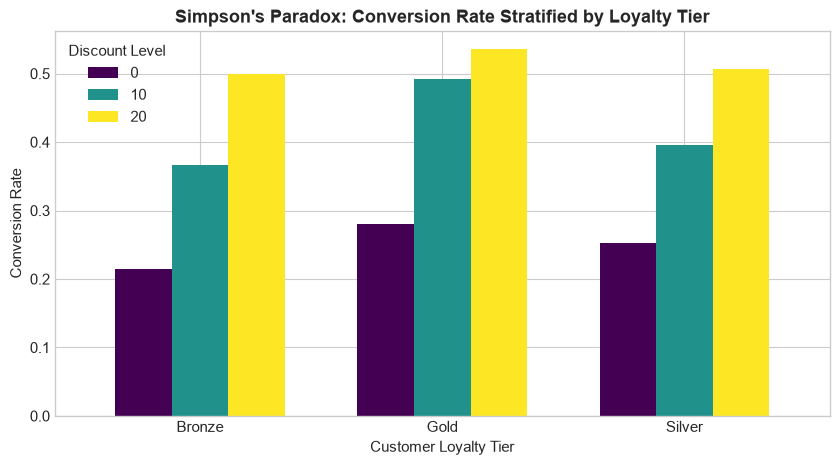

In [6]:
stratified = df.groupby(['loyalty_tier', 'discount'])['purchase'].mean().unstack()

fig, ax = plt.subplots(figsize=(10, 5))
stratified.plot(kind='bar', ax=ax, colormap='viridis', width=0.7)
ax.set_title("Simpson's Paradox: Conversion Rate Stratified by Loyalty Tier", fontweight="bold")
ax.set_ylabel("Conversion Rate")
ax.set_xlabel("Customer Loyalty Tier")
plt.xticks(rotation=0)
plt.legend(title="Discount Level")
plt.show()


## 3. Structural Causal Model (DAG) & Identification

We model the data generation mechanism as a Directed Acyclic Graph (DAG) with:
- **Treatment ($T$)**: `discount` $\in \{0, 10, 20\}$
- **Outcome ($Y$)**: `purchase` $\in \{0, 1\}$
- **Confounders ($X$)**: `past_spend`, `recency_days`, `loyalty_tier`, `category_affinity`
- **Effect Modifiers ($W$)**: `age`, `past_spend`, `loyalty_tier`

Using **DoWhy**, we formalize the identification via the **Backdoor Criterion**:
$$P(Y \mid \text{do}(T = t)) = \sum_{x} P(Y \mid T = t, X = x) P(X = x)$$


In [7]:
# Display DAG DOT specification
dag_dot = get_dag_dot()
print("DAG DOT Representation:")
print(dag_dot)


DAG DOT Representation:
digraph {
    past_spend -> discount;
    recency_days -> discount;
    loyalty_tier -> discount;
    category_affinity -> discount;
    past_spend -> purchase;
    recency_days -> purchase;
    loyalty_tier -> purchase;
    category_affinity -> purchase;
    age -> purchase;
    discount -> purchase;
}


In [8]:
# Build CausalModel using DoWhy integration
causal_model = build_dag(df, treatment='discount', outcome='purchase')

# Identify causal effect via Backdoor Criterion
identified_estimand = identify_effect(causal_model)
print("Causal Identification Summary:")
print(f"Treatment: {causal_model._treatment}")
print(f"Outcome: {causal_model._outcome}")
print(f"Backdoor adjustment variables: {identified_estimand.get_backdoor_variables()}")


Causal Identification Summary:
Treatment: ['discount']
Outcome: ['purchase']
Backdoor adjustment variables: ['category_affinity', 'recency_days', 'loyalty_tier', 'past_spend']


## 4. Propensity Score Modeling & Overlap Diagnostics

To adjust for confounding, we estimate the generalized propensity scores:
$$e_t(X) = P(T = t \mid X)$$
using multinomial logistic regression with one-hot encoded categorical variables.

### The Positivity Assumption
For valid causal identification, every customer must have a non-zero probability of receiving every treatment arm:
$$0 < P(T = t \mid X = x) < 1 \quad \forall t, x$$


In [9]:
# Fit multi-class propensity model
clf, propensities_df, ipw_weights = fit_propensity(df, treatment_col='discount')

print("Fitted Propensities (first 5 rows):")
display(propensities_df.head(5))


Fitted Propensities (first 5 rows):


,prob_0,prob_10,prob_20
0,0.553077,0.298622,0.148300
1,0.480554,0.305645,0.213801
2,0.362106,0.385677,0.252217
3,0.232476,0.425488,0.342035
4,0.545672,0.304654,0.149675


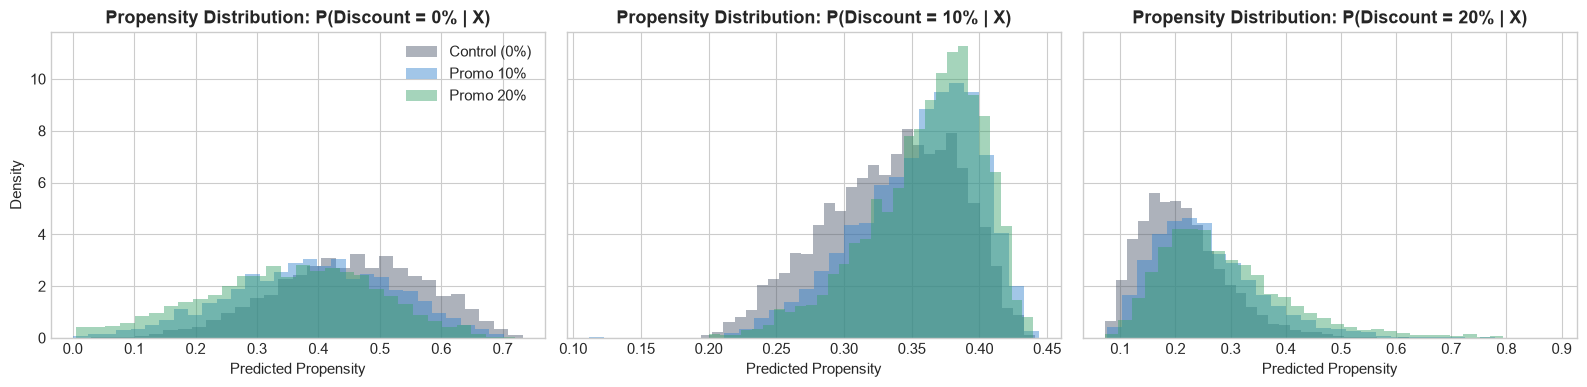

In [10]:
# Positivity & Common Support Overlap Inspection
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

for idx, arm in enumerate([0, 10, 20]):
    ax = axes[idx]
    col = f"prob_{arm}"
    for actual_arm, color, label in [(0, '#4A5568', 'Control (0%)'), (10, '#3182CE', 'Promo 10%'), (20, '#38A169', 'Promo 20%')]:
        mask = df['discount'] == actual_arm
        ax.hist(propensities_df.loc[mask, col], bins=30, alpha=0.45, color=color, density=True, label=label)
    ax.set_title(f"Propensity Distribution: P(Discount = {arm}% | X)", fontweight="bold")
    ax.set_xlabel("Predicted Propensity")
    if idx == 0:
        ax.set_ylabel("Density")
        ax.legend()

plt.tight_layout()
plt.show()


In [11]:
# Covariate Balance Evaluation (Standardized Mean Difference)
balance_rep = balance_table(df, treatment_col='discount', confounders=CONFOUNDERS)
print("Standardized Mean Differences (SMD) before weighting:")
display(balance_rep)


Standardized Mean Differences (SMD) before weighting:


,feature,unweighted_smd_10_vs_0,unweighted_smd_20_vs_0,balanced_target_met
0,past_spend,0.3501,0.5549,False
1,recency_days,0.2718,0.3670,False
2,loyalty_tier_Gold,0.0926,0.2034,False
3,loyalty_tier_Silver,0.0808,0.0829,True
4,category_affinity,0.0022,0.0729,True


## 5. Inverse Probability Weighting (IPW) & Ground Truth Benchmark

Using Horvitz-Thompson Inverse Probability Weighting (IPW), we weight each observation by the inverse of the propensity of receiving the assigned treatment:
$$w_i = \frac{1}{e_{T_i}(X_i)}$$

We can then compute the de-biased Average Treatment Effect (ATE):
$$\widehat{\text{ATE}}_{\text{IPW}}(t) = \frac{\sum_{i: T_i = t} w_i Y_i}{\sum_{i: T_i = t} w_i} - \frac{\sum_{i: T_i = 0} w_i Y_i}{\sum_{i: T_i = 0} w_i}$$


In [12]:
# Compute True ATE from synthetic potential outcomes
true_ate_10 = (compute_true_uplift(df['past_spend'].values, df['loyalty_tier'].values, df['age'].values, 10)).mean()
true_ate_20 = (compute_true_uplift(df['past_spend'].values, df['loyalty_tier'].values, df['age'].values, 20)).mean()

# Naive ATE
naive_ate_10 = df.loc[df['discount'] == 10, 'purchase'].mean() - df.loc[df['discount'] == 0, 'purchase'].mean()
naive_ate_20 = df.loc[df['discount'] == 20, 'purchase'].mean() - df.loc[df['discount'] == 0, 'purchase'].mean()

# IPW-adjusted ATE (stabilized / normalized)
w_0 = ipw_weights[df['discount'] == 0]
y_0 = df.loc[df['discount'] == 0, 'purchase'].values
w_10 = ipw_weights[df['discount'] == 10]
y_10 = df.loc[df['discount'] == 10, 'purchase'].values
w_20 = ipw_weights[df['discount'] == 20]
y_20 = df.loc[df['discount'] == 20, 'purchase'].values

ipw_mean_0 = np.average(y_0, weights=w_0)
ipw_mean_10 = np.average(y_10, weights=w_10)
ipw_mean_20 = np.average(y_20, weights=w_20)

ipw_ate_10 = ipw_mean_10 - ipw_mean_0
ipw_ate_20 = ipw_mean_20 - ipw_mean_0

ate_benchmark = pd.DataFrame({
    'Metric': ['ATE: Discount 10% vs 0%', 'ATE: Discount 20% vs 0%'],
    'Naive Estimator': [naive_ate_10, naive_ate_20],
    'IPW Estimator': [ipw_ate_10, ipw_ate_20],
    'True Synthetic ATE': [true_ate_10, true_ate_20],
    'Naive Bias': [naive_ate_10 - true_ate_10, naive_ate_20 - true_ate_20],
    'IPW Bias': [ipw_ate_10 - true_ate_10, ipw_ate_20 - true_ate_20]
})

display(ate_benchmark.round(4))


,Metric,Naive Estimator,IPW Estimator,True Synthetic ATE,Naive Bias,IPW Bias
0,ATE: Discount 10% vs 0%,0.1616,0.0847,0.0874,0.0741,-0.0027
1,ATE: Discount 20% vs 0%,0.2743,0.1562,0.1457,0.1286,0.0105


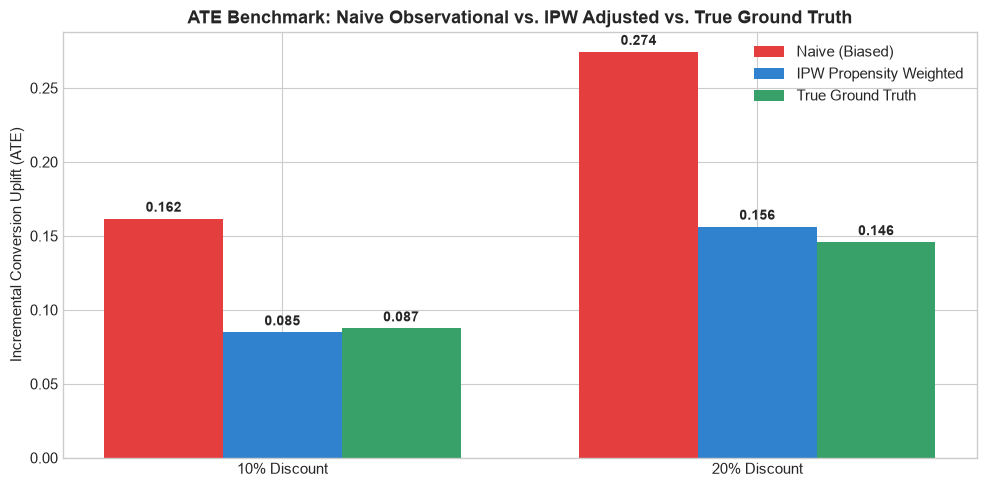

In [13]:
# Visualization: Comparison of Estimators vs Ground Truth
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(2)
width = 0.25

rects1 = ax.bar(x - width, ate_benchmark['Naive Estimator'], width, label='Naive (Biased)', color='#E53E3E')
rects2 = ax.bar(x, ate_benchmark['IPW Estimator'], width, label='IPW Propensity Weighted', color='#3182CE')
rects3 = ax.bar(x + width, ate_benchmark['True Synthetic ATE'], width, label='True Ground Truth', color='#38A169')

ax.set_ylabel('Incremental Conversion Uplift (ATE)')
ax.set_title('ATE Benchmark: Naive Observational vs. IPW Adjusted vs. True Ground Truth', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(['10% Discount', '20% Discount'])
ax.legend()

for rects in [rects1, rects2, rects3]:
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


## 💡 Summary & Bridge to Walkthrough 02

### Key Takeaways:
1. **Naive comparisons severely overstate treatment effects** (by over 2x-3x) due to selection bias where high-value customers are disproportionately offered discounts.
2. **Propensity Score Weighting (IPW)** successfully eliminates confounding bias for population-level Average Treatment Effects (ATE).
3. **Limitation of IPW**: While IPW yields unbiased ATE, real-world marketing requires **heterogeneous personalization**: we need to know *which specific customers* respond to which discounts.

👉 In **`notebooks/02_double_machine_learning_uplift.ipynb`**, we advance to **Double Machine Learning (Chernozhukov et al.)** with LightGBM and Causal Forests to estimate customer-level **Conditional Average Treatment Effects (CATE)**!
